In [7]:

#loading dataset
import openml
import pandas as pd

dset=openml.datasets.get_dataset(45950)
X, y, categorical, attribute_names = dset.get_data(target=dset.default_target_attribute, dataset_format='dataframe')
df = X.copy()
df['target'] = y

# View the Dataset
df.head()
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       5000 non-null   float64
 1   anaemia                   5000 non-null   uint8  
 2   creatinine_phosphokinase  5000 non-null   int64  
 3   diabetes                  5000 non-null   uint8  
 4   ejection_fraction         5000 non-null   uint8  
 5   high_blood_pressure       5000 non-null   uint8  
 6   platelets                 5000 non-null   float64
 7   serum_creatinine          5000 non-null   float64
 8   serum_sodium              5000 non-null   uint8  
 9   sex                       5000 non-null   uint8  
 10  smoking                   5000 non-null   uint8  
 11  time                      5000 non-null   int64  
 12  DEATH_EVENT               5000 non-null   uint8  
 13  target                    0 non-null      object 
dtypes: float

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,60.288736,0.474400,586.760600,0.439400,37.734600,0.364800,265075.404370,1.369106,136.808200,0.645600,0.311800,130.678800,0.313600
std,11.697243,0.499394,976.733979,0.496364,11.514855,0.481422,97999.758622,1.009750,4.464236,0.478379,0.463275,77.325928,0.464002
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.500000,113.000000,0.000000,0.000000,4.000000,0.000000
25%,50.000000,0.000000,121.000000,0.000000,30.000000,0.000000,215000.000000,0.900000,134.000000,0.000000,0.000000,74.000000,0.000000
50%,60.000000,0.000000,248.000000,0.000000,38.000000,0.000000,263358.030000,1.100000,137.000000,1.000000,0.000000,113.000000,0.000000
75%,68.000000,1.000000,582.000000,1.000000,45.000000,1.000000,310000.000000,1.400000,140.000000,1.000000,1.000000,201.000000,1.000000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.400000,148.000000,1.000000,1.000000,285.000000,1.000000


pre-processiong and cleaning data


In [12]:
import openml
import pandas as pd
from sklearn.model_selection import train_test_split

dset=openml.datasets.get_dataset(45950)
X, y, categorical, attribute_names = dset.get_data(target=dset.default_target_attribute, dataset_format='dataframe')
df = X.copy()
df['target'] = y

# View the Dataset
df.head()
df.info()
df.describe()
# checking for missing values in the dattaset
df.isnull().sum()



categorical_columns= df.select_dtypes(include=['object', 'category']).columns
print("Categorical columns:", categorical_columns)


# For linear regression and MLP categorising to binary

df = pd.get_dummies(df, drop_first=True)
print(df.head())



X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)









<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       5000 non-null   float64
 1   anaemia                   5000 non-null   uint8  
 2   creatinine_phosphokinase  5000 non-null   int64  
 3   diabetes                  5000 non-null   uint8  
 4   ejection_fraction         5000 non-null   uint8  
 5   high_blood_pressure       5000 non-null   uint8  
 6   platelets                 5000 non-null   float64
 7   serum_creatinine          5000 non-null   float64
 8   serum_sodium              5000 non-null   uint8  
 9   sex                       5000 non-null   uint8  
 10  smoking                   5000 non-null   uint8  
 11  time                      5000 non-null   int64  
 12  DEATH_EVENT               5000 non-null   uint8  
 13  target                    0 non-null      object 
dtypes: float

MODELS

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       5000 non-null   float64
 1   anaemia                   5000 non-null   uint8  
 2   creatinine_phosphokinase  5000 non-null   int64  
 3   diabetes                  5000 non-null   uint8  
 4   ejection_fraction         5000 non-null   uint8  
 5   high_blood_pressure       5000 non-null   uint8  
 6   platelets                 5000 non-null   float64
 7   serum_creatinine          5000 non-null   float64
 8   serum_sodium              5000 non-null   uint8  
 9   sex                       5000 non-null   uint8  
 10  smoking                   5000 non-null   uint8  
 11  time                      5000 non-null   int64  
 12  DEATH_EVENT               5000 non-null   uint8  
 13  target                    0 non-null      object 
dtypes: float

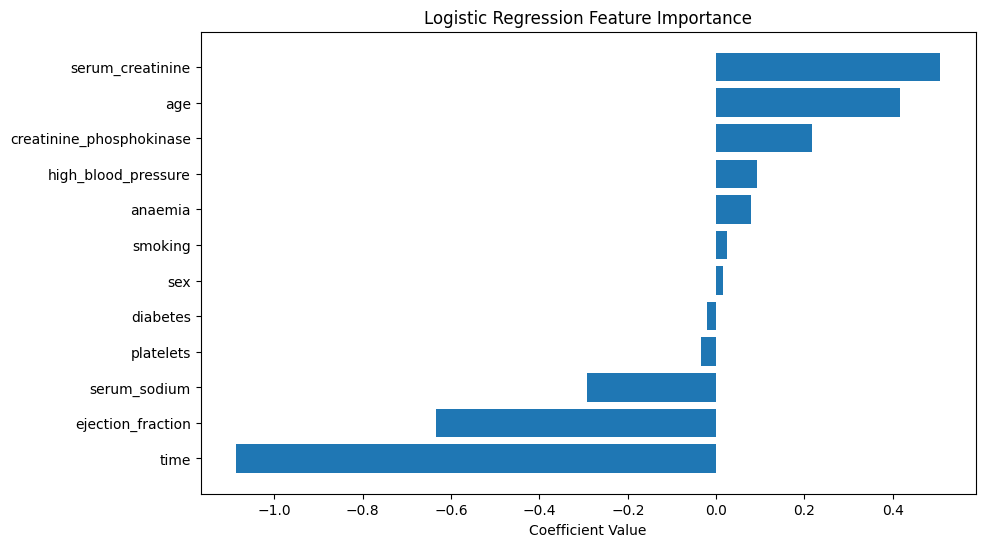

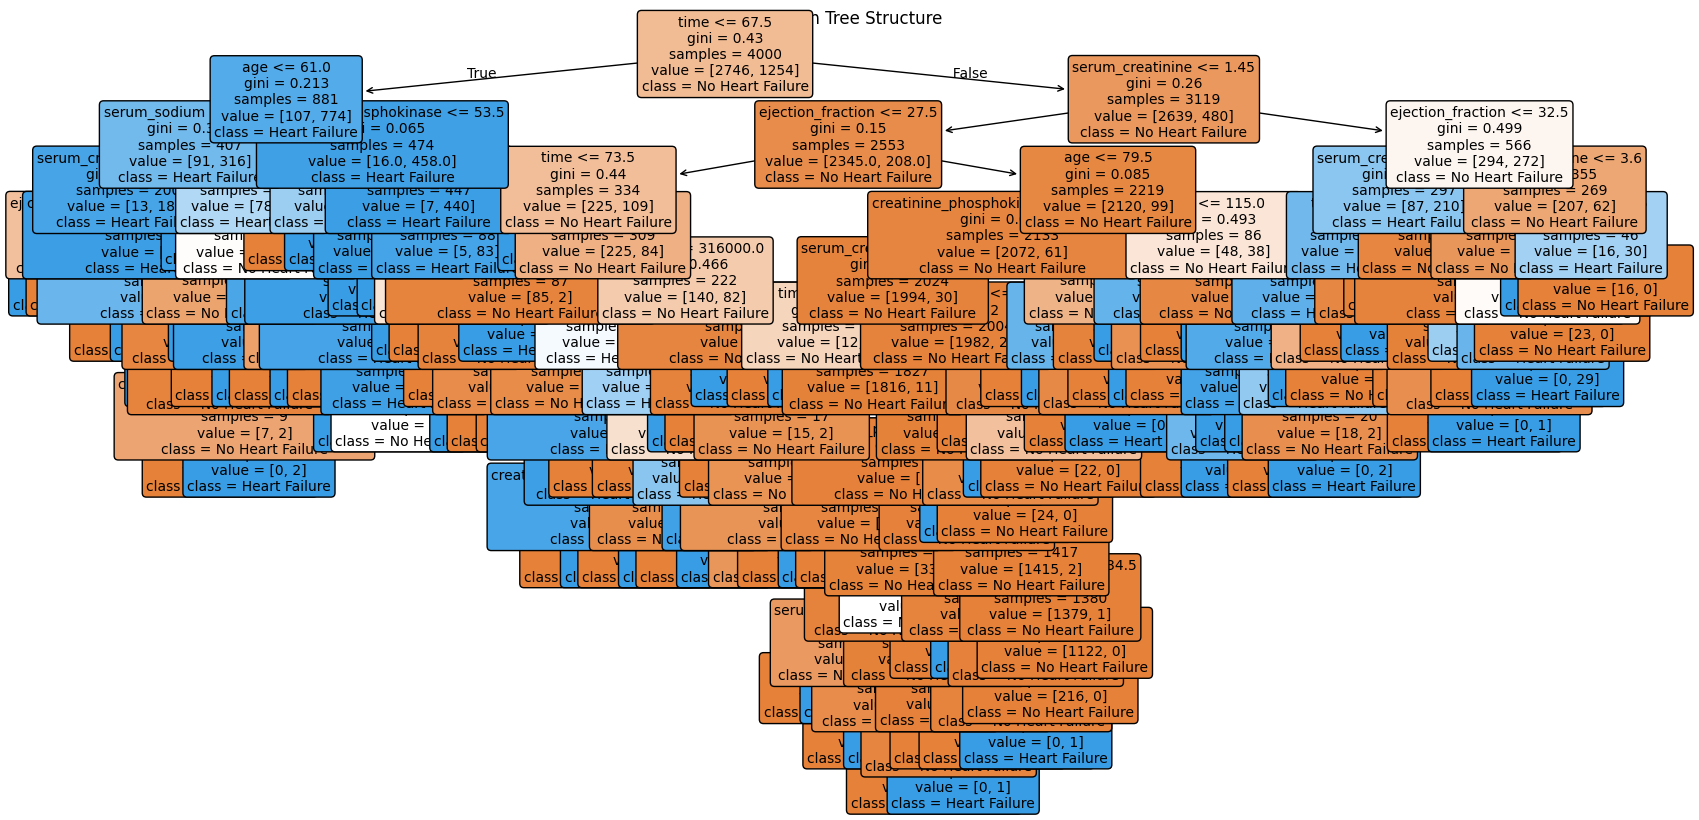

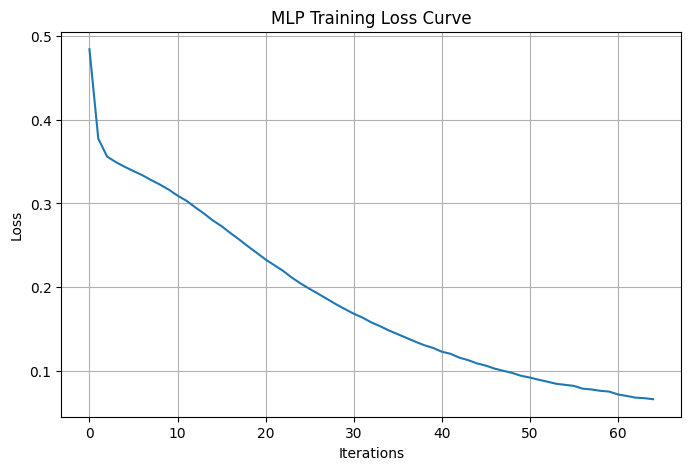

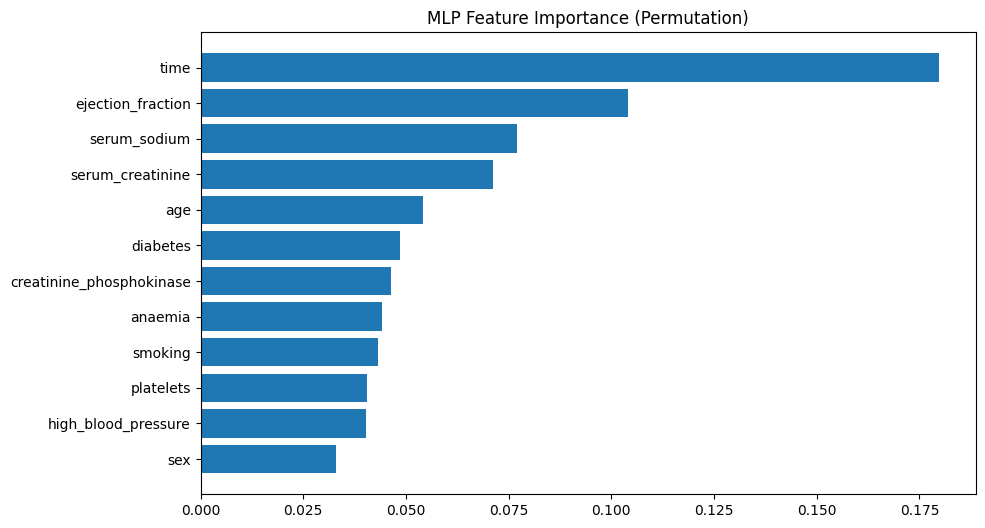

In [2]:
import openml
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import plot_tree
from sklearn.inspection import permutation_importance

dset=openml.datasets.get_dataset(45950)
X, y, categorical, attribute_names = dset.get_data(target=dset.default_target_attribute, dataset_format='dataframe')
df = X.copy()
df['target'] = y

# View the Dataset
df.head()
df.info()
df.describe()
# checking for missing values in the dattaset
df.isnull().sum()



categorical_columns= df.select_dtypes(include=['object', 'category']).columns
print("Categorical columns:", categorical_columns)


# For linear regression and MLP categorising to binary

df = pd.get_dummies(df, drop_first=True)
print(df.head())



X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)




# Decision tree model


param_grid_decision_tree = {'max_depth': [3, 5, 7, 9, None],
                 'min_samples_split': [2, 5, 10]}
dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_decision_tree, cv=5, scoring='accuracy')
dt.fit(X_train, y_train)
dt_best_params = dt.best_params_
dt_best_score = dt.best_score_
print("Best parameters for Decision Tree:", dt_best_params)







# scaling for NLP and Regression Model
scale = StandardScaler()
X_train_scaled = scale.fit_transform(X_train)
X_test_scaled = scale.transform(X_test)





# Regression Model

param_grid_lr = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['liblinear']}
lr = GridSearchCV(LogisticRegression(), param_grid_lr, cv=5, scoring='accuracy')
lr.fit(X_train_scaled, y_train)




# MLP Neutral Network
param_grid_mlp = {
    'hidden_layer_sizes': [(50,), (100,), (50,50)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001],
    'learning_rate': ['constant','adaptive']
}
mlp = GridSearchCV(
    MLPClassifier(max_iter=1000, early_stopping=True, random_state=42),
    param_grid_mlp,
    cv=5,
    scoring='accuracy'
)
mlp.fit(X_train_scaled, y_train)
print("Best MLP params:", mlp.best_params_)





coefficients = lr.best_estimator_.coef_[0]
features = X.columns

coef_df = pd.DataFrame({'Feature': features, 'Coefficient': coefficients})
coef_df = coef_df.sort_values(by='Coefficient', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(coef_df['Feature'], coef_df['Coefficient'])
plt.title('Logistic Regression Feature')
plt.xlabel('Coefficient Value')
plt.gca().invert_yaxis()
plt.show()


 #Decision Tree Visual

plt.figure(figsize=(20,10))
plot_tree(dt.best_estimator_,
          feature_names=X.columns,
          class_names=['No Heart Failure', 'Heart Failure'],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree Structure")
plt.show()


 #MLP  Visual

# a) Training loss curve
mlp_best = mlp.best_estimator_
plt.figure(figsize=(8,5))
plt.plot(mlp_best.loss_curve_)
plt.title('MLP Training Loss Curve')
plt.xlabel('Iterations')
plt.grid(True)
plt.show()

# b) Feature importance via permutation
result = permutation_importance(mlp_best, X_test_scaled, y_test, n_repeats=10, random_state=42)
importances = result.importances_mean
indices = np.argsort(importances)

plt.figure(figsize=(10,6))
plt.barh(np.array(X.columns)[indices], importances[indices])
plt.title("MLP Feature Importance (Permutation)")
plt.show()














